# **Member 3 - Modelling, Cross-validation and Hyper Parameter tuning**

Environment Setup and Loading Previous Pipeline artifacts

In [1]:
# Google Drive setup
import os
from google.colab import drive
import shutil
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/My Drive/ML & DWBI Assignment/ML Assignment"
MEMBER_1_DIR = os.path.join(PROJECT_DIR, "IT24102060")
MEMBER_2_DIR = os.path.join(PROJECT_DIR, "IT24101461")
DRIVE_DIR = os.path.join(PROJECT_DIR, "IT24102228_new_folder")

os.makedirs(MEMBER_1_DIR, exist_ok=True)
os.makedirs(MEMBER_2_DIR, exist_ok=True)
os.makedirs(DRIVE_DIR, exist_ok=True)

# Keep the original coding unchanged by linking only the required input artifacts

member_1_files = [
    "ds52-preprocessor.joblib",
    "ds52-train_test_split.joblib"
]

member_2_files = [
    "IT24101461_engineered_data.joblib",
    "IT24101461_feature_pipeline.joblib",
    "IT24101461_selected_data.joblib"
]

for file_name in member_1_files:
    source_path = os.path.join(MEMBER_1_DIR, file_name)
    link_path = os.path.join(DRIVE_DIR, file_name)

    if os.path.exists(source_path):
        if os.path.exists(link_path):
            os.remove(link_path)
        shutil.copy2(source_path, link_path)
    else:
        print(f"Warning: Source file not found: {source_path}")


for file_name in member_2_files:
    source_path = os.path.join(MEMBER_2_DIR, file_name)
    link_path = os.path.join(DRIVE_DIR, file_name)

    if os.path.exists(source_path):
        if os.path.exists(link_path):
            os.remove(link_path)
        shutil.copy2(source_path, link_path)
    else:
        print(f"Warning: Source file not found: {source_path}")

os.chdir(DRIVE_DIR)
print("Member 1 input folder:", MEMBER_1_DIR)
print("Member 2 input folder:", MEMBER_2_DIR)
print("Member 3 output folder:", DRIVE_DIR)
print("All member 3 generated files will be saved seperately in Member_3.")

# Environment Setup
import warnings
import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import(StratifiedKFold, cross_validate, GridSearchCV, RandomizedSearchCV)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import(accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, classification_report)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("✅ Member 3 modelling environment initialized")
print("Random State:", RANDOM_STATE)

Mounted at /content/drive
Member 1 input folder: /content/drive/My Drive/ML & DWBI Assignment/ML Assignment/IT24102060
Member 2 input folder: /content/drive/My Drive/ML & DWBI Assignment/ML Assignment/IT24101461
Member 3 output folder: /content/drive/My Drive/ML & DWBI Assignment/ML Assignment/IT24102228_new_folder
All member 3 generated files will be saved seperately in Member_3.
✅ Member 3 modelling environment initialized
Random State: 42


Import XGBoost and LightGBM

In [2]:
try:
  from xgboost import XGBClassifier
  print("✅ XGBoost imported successfully")
except ImportError:
  print("❌ XGBoost is not installed")

try:
  from lightgbm import LGBMClassifier
  print("✅ LightGBM imported successfully")
except ImportError:
  print("❌ LightGBM is not installed")

✅ XGBoost imported successfully
✅ LightGBM imported successfully


Check Member 1 and Member 2 files

In [3]:
required_files = [
    "ds52-preprocessor.joblib",
    "ds52-train_test_split.joblib",
    "IT24101461_engineered_data.joblib",
    "IT24101461_feature_pipeline.joblib",
    "IT24101461_selected_data.joblib"
]

print("PREVIOUS MEMBER ARTIFACT CHECK")
print("=" * 60)

for file in required_files:
  if os.path.exists(file):
    size_kb = os.path.getsize(file) / 1024
    print(f"✅ {file:<45} {size_kb:.2f} KB")
  else:
    print(f"❌ {file:<45} NOT FOUND")

PREVIOUS MEMBER ARTIFACT CHECK
✅ ds52-preprocessor.joblib                      5.83 KB
✅ ds52-train_test_split.joblib                  4685.68 KB
✅ IT24101461_engineered_data.joblib             5882.25 KB
✅ IT24101461_feature_pipeline.joblib            9.04 KB
✅ IT24101461_selected_data.joblib               12011.67 KB


Load Member 2 Joblib files

In [4]:
engineered_data = joblib.load("IT24101461_engineered_data.joblib")
feature_pipeline = joblib.load("IT24101461_feature_pipeline.joblib")
selected_data = joblib.load("IT24101461_selected_data.joblib")

print("✅ Member 2 files loaded successfully")

✅ Member 2 files loaded successfully


Inspect What is inside Each .joblib

In [5]:
artifacts = {
    "engineered_data": engineered_data,
    "feature_pipeline": feature_pipeline,
    "selected_data": selected_data
}

print("MEMBER 2 ARTIFACT INSPECTION")
print("=" * 60)

for name, obj in artifacts.items():

  print(f"\n{name}")
  print("-" * 60)

  print("Python type:")
  print(type(obj))

  if isinstance(obj, dict):
    print("\nAvailable dictionary keys:")
    print(list(Obj.keys()))

  elif isinstance(obj, pd.DataFrame):
    print("\nShape:")
    print(obj.shape)

    print("\nColumns:")
    print(obj.columns.tolist())

  elif isinstance(obj, (list, tuple)):
    print("\nNumber of elements:")
    print(len(obj))

    for i, item in enumerate(obj):
      print(f"Element {i}: {type(item)}")

  else:
    print("\nObject")
    print(obj)

MEMBER 2 ARTIFACT INSPECTION

engineered_data
------------------------------------------------------------
Python type:
<class 'tuple'>

Number of elements:
4
Element 0: <class 'pandas.core.frame.DataFrame'>
Element 1: <class 'pandas.core.frame.DataFrame'>
Element 2: <class 'pandas.core.series.Series'>
Element 3: <class 'pandas.core.series.Series'>

feature_pipeline
------------------------------------------------------------
Python type:
<class 'sklearn.pipeline.Pipeline'>

Object
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(force_int_remainder_cols='deprecated',
                                   transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),


Verify Leakage Safety

In [6]:
print("LEKAGE SAFETY CHECK")
print("=" * 60)

def check_duration(obj, name):
  if isinstance(obj, pd.DataFrame):

    if "duration" in obj.columns:
      print(f"⚠️ WARNING: 'duration' found in {name}")
    else:
      print(f"✅ 'duration' is not present in {name}")

  elif isinstance(obj, dict):

      found = False

      for key, value in obj.items():

        if isinstance(value, pd.DataFrame):
          if "duration" in value.columns:
            print(f"⚠️ WARNING: 'duration' found in" f"{name} -> {key}")
            found = True

      if not found:
        print(f"✅ No DataFrame containing 'duration'" f"was detected in {name}")

for name, obj in artifacts.items():
  check_duration(obj, name)

LEKAGE SAFETY CHECK


# Task 2 - Extract and Validate Modelling Data

Inspect slected_data first

In [7]:
print("=" * 70)
print("SELECTED DATA STRUCTURE")
print("=" * 70)

print("Object type:", type(selected_data))

if isinstance(selected_data, dict):

  print("\nAvailable keys:")

  for key, value in selected_data.items():

    print(f"{key:<25}"f"Type:{type(value)._name_:<20}"f"Shape:{getattr(value, 'shape', 'N/A')}")

elif isinstance(selected_data, (list, tuple)):

  print("\nNumber of objects:", len(selected_data))

  for i, value in enumerate(selected_data):
    print(f"Object {i:<3} Type: {type(value).__name__:<20} Shape: {getattr(value, 'shape', 'N/A')}")

else:
  print("\nShape:", getattr(selected_data, "shape", "N/A"))

SELECTED DATA STRUCTURE
Object type: <class 'tuple'>

Number of objects: 5
Object 0   Type: ndarray              Shape: (36168, 30)
Object 1   Type: ndarray              Shape: (9043, 30)
Object 2   Type: Series               Shape: (36168,)
Object 3   Type: Series               Shape: (9043,)
Object 4   Type: ndarray              Shape: (30,)


Automatically find X/y train/test objects

In [8]:
train_test_data = joblib.load("ds52-train_test_split.joblib")

print("=" * 70)
print("TRAIN / TEST SPLIT ARTIFACT")
print("=" * 70)

print("Object type:", type(train_test_data))

TRAIN / TEST SPLIT ARTIFACT
Object type: <class 'tuple'>


Fallback to engineered_data

In [9]:
print("\n" + "=" * 70)
print("TRAIN / TEST SPLIT STRUCTURE")
print("=" * 70)

if isinstance(train_test_data, dict):

  print("\nAvailable keys:")

  for key, value in train_test_data.items():
    print(f"{key:<30}" f"Type: {type(value)._name_:<20}" f"Shape: {getattr(value, 'shape', 'N/A')}")

elif isinstance(train_test_data, (list, tuple)):

  print("\nNumber of stored objects:", len(train_test_data))

  for i, value in enumerate(train_test_data):

    print(f"Object {i:<3} Type: {type(value).__name__:<20} Shape: {getattr(value, 'shape', 'N/A')}")

else:
  print("Stored object type:", type(train_test_data))
  print("Shape:", getattr(train_test_data, "shape", "N/A"))


TRAIN / TEST SPLIT STRUCTURE

Number of stored objects: 4
Object 0   Type: DataFrame            Shape: (36168, 15)
Object 1   Type: DataFrame            Shape: (9043, 15)
Object 2   Type: Series               Shape: (36168,)
Object 3   Type: Series               Shape: (9043,)


Extract the four datasets

In [10]:
X_train, X_test, y_train, y_test = train_test_data

print("=" * 70)
print("DATA EXTRACTED SUCCESSFULL")
print("=" * 70)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

print("\n✅ Train/Test data extracted successfully")

DATA EXTRACTED SUCCESSFULL
X_train shape: (36168, 15)
X_test shape: (9043, 15)
y_train shape: (36168,)
y_test shape: (9043,)

✅ Train/Test data extracted successfully


Check features and leakage

In [11]:
print("=" * 70)
print("FEATURE VALIDATION")
print("=" * 70)

print("\nTraining features:")
print(X_train.columns.tolist())

print("\nNumber of features:", X_train.shape[1])

if "duration" in X_train.columns:
  print("\n❌ WARNING: 'duration' exists in X_train")
else:
  print("\n✅ 'duration' is not present in X_train")

if "duration" in X_test.columns:
  print("\n❌ WARNING: 'duration' exists in X_test")
else:
  print("\n✅ 'duration' is not present in X_test")

FEATURE VALIDATION

Training features:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']

Number of features: 15

✅ 'duration' is not present in X_train

✅ 'duration' is not present in X_test


check class distribution

In [12]:
print("=" * 70)
print("CLASS DISTRIBUTION")
print("=" * 70)

print("\nTraining Set")
print("-" * 40)

train_counts = y_train.value_counts()
train_percent = y_train.value_counts(normalize = True) * 100

for label in train_counts.index:
  print(f"{label}: {train_counts[label]}" f"({train_percent[label]:.2f}%)")

print("\nTest Set")
print("-" * 40)

test_counts = y_test.value_counts()
test_percent = y_test.value_counts(normalize = True) * 100

for label in test_counts.index:
  print(f"{label}: {test_counts[label]}" f"({test_percent[label]:.2f}%)")

CLASS DISTRIBUTION

Training Set
----------------------------------------
0: 31937(88.30%)
1: 4231(11.70%)

Test Set
----------------------------------------
0: 7985(88.30%)
1: 1058(11.70%)


Missing values

In [13]:
print("=" * 70)
print("MISSING VALUE CHECK")
print("=" * 70)

print("X_train missing values:", X_train.isnull().sum().sum())

print("X_test missing values:", X_test.isnull().sum().sum())

print("y_train missing values:", y_train.isnull().sum())

print("y_test missing values:", y_test.isnull().sum())

MISSING VALUE CHECK
X_train missing values: 0
X_test missing values: 0
y_train missing values: 0
y_test missing values: 0


Verify binary target

In [14]:
print("=" * 70)
print("TARGET VALIDATION")

print("Training target classes:", y_train.unique())

print("Test target classes:", y_test.unique())

if y_train.nunique() == 2 and y_test.nunique() == 2:
  print("\n✅ Binary Classification target confirmed")
else:
  print("\n❌ Target requires further inspection")

TARGET VALIDATION
Training target classes: [0 1]
Test target classes: [0 1]

✅ Binary Classification target confirmed


Final Task 2 summary

In [15]:
print("=" * 70)
print("MEMBER 3 - TASK 2 COMPLETED")
print("=" * 70)

print(f"""
✅ Training samples : {len(X_train)}
✅ Testing samples  : {len(X_test)}
✅ Input features   : {X_train.shape[1]}
✅ Train/test targets successfully extracted
✅ Binary classification target validated
✅ Leakage feature checked
✅ Missing values checked

Member 3 modelling data is ready.

Next:
TASK 3 - LOGISTIC REGRESSION BASELINE MODEL
""")

MEMBER 3 - TASK 2 COMPLETED

✅ Training samples : 36168
✅ Testing samples  : 9043
✅ Input features   : 15
✅ Train/test targets successfully extracted
✅ Binary classification target validated
✅ Leakage feature checked
✅ Missing values checked

Member 3 modelling data is ready.

Next:
TASK 3 - LOGISTIC REGRESSION BASELINE MODEL



# Task 3 - Baseline Model Development and Comparison

Encode target if necessary

In [16]:
print("=" * 70)
print("TARGET PREPARATION")
print("=" * 70)

print("Current training labels:", y_train.unique())

if y_train.dtype == "object":

    target_mapping = {
        "no": 0,
        "yes": 1
    }

    y_train = y_train.map(target_mapping)
    y_test = y_test.map(target_mapping)

    print("✅ Target converted: no=0, yes=1")

else:

    print("✅ Target already numerically encoded")

print("Final training labels:", y_train.unique())
print("Final testing labels :", y_test.unique())

TARGET PREPARATION
Current training labels: [0 1]
✅ Target already numerically encoded
Final training labels: [0 1]
Final testing labels : [0 1]


Load and Clone Member 2 Feature Pipeline

In [17]:
from sklearn.base import clone

feature_pipeline = joblib.load(
    "IT24101461_feature_pipeline.joblib"
)

print("=" * 70)
print("MEMBER 2 PIPELINE LOADED")
print("=" * 70)

print(type(feature_pipeline))
print("\n✅ Existing feature pipeline ready")

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("=" * 70)
print("PIPELINE COMPATIBILITY CHECK")
print("=" * 70)


def repair_column_transformer(obj):

    repaired = 0

    # Direct ColumnTransformer
    if isinstance(obj, ColumnTransformer):

        if hasattr(obj, "force_int_remainder_cols"):

            current_value = getattr(
                obj,
                "force_int_remainder_cols"
            )

            print(
                "Found ColumnTransformer "
                f"force_int_remainder_cols={current_value}"
            )

            if current_value == "deprecated":

                obj.force_int_remainder_cols = False
                repaired += 1

                print(
                    "✅ Changed "
                    "force_int_remainder_cols to False"
                )

        # Check nested transformers
        if hasattr(obj, "transformers"):

            for _, transformer, _ in obj.transformers:

                if transformer not in [
                    "drop",
                    "passthrough"
                ]:

                    repaired += repair_column_transformer(
                        transformer
                    )

    # Pipeline
    elif isinstance(obj, Pipeline):

        for _, step in obj.steps:

            repaired += repair_column_transformer(
                step
            )

    return repaired


repairs = repair_column_transformer(
    feature_pipeline
)

print("\n" + "=" * 70)

if repairs > 0:

    print(
        f"✅ Compatibility repairs applied: {repairs}"
    )

else:

    print(
        "✅ No incompatible ColumnTransformer "
        "parameter detected"
    )

print("=" * 70)

from sklearn.base import clone

print("=" * 70)
print("TESTING REPAIRED FEATURE PIPELINE")
print("=" * 70)

try:

    test_pipeline = clone(
        feature_pipeline
    )

    X_sample = X_train.iloc[:500].copy()
    y_sample = y_train.iloc[:500].copy()

    test_pipeline.fit(
        X_sample,
        y_sample
    )

    X_sample_transformed = (
        test_pipeline.transform(X_sample)
    )

    print("✅ Feature pipeline fitted successfully")

    print(
        "Input shape      :",
        X_sample.shape
    )

    print(
        "Transformed shape:",
        X_sample_transformed.shape
    )

    PIPELINE_READY = True

except Exception as e:

    PIPELINE_READY = False

    print("❌ Pipeline test failed")
    print()
    print(type(e).__name__)
    print(e)

MEMBER 2 PIPELINE LOADED
<class 'sklearn.pipeline.Pipeline'>

✅ Existing feature pipeline ready
PIPELINE COMPATIBILITY CHECK
Found ColumnTransformer force_int_remainder_cols=deprecated
✅ Changed force_int_remainder_cols to False

✅ Compatibility repairs applied: 1
TESTING REPAIRED FEATURE PIPELINE
❌ Pipeline test failed

ValueError
A given column is not a column of the dataframe


Import All Four Models

In [18]:
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.model_selection import(StratifiedKFold, cross_validate)

from sklearn.metrics import(accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score)

print("✅ Logistic Regression ready")
print("✅ Random Forest ready")
print("✅ XGBoost ready")
print("✅ LightGBM ready")

✅ Logistic Regression ready
✅ Random Forest ready
✅ XGBoost ready
✅ LightGBM ready


Configure Four Baseline Models

In [19]:
models = {"Logistic Regression": LogisticRegression(class_weight = "balanced", max_iter = 2000, random_state = RANDOM_STATE),
          "Random Forest": RandomForestClassifier(n_estimators =300, class_weight = "balanced", random_state = RANDOM_STATE, n_jobs = -1),
          "XGBoost": XGBClassifier(n_estimators = 300, max_depth = 6, learning_rate = 0.1, random_state = RANDOM_STATE, eval_metric = "logloss", n_jobs = -1),
          "LightGBM": LGBMClassifier(n_estimators = 300, learning_rate = 0.1, class_weight = "balanced", random_state = RANDOM_STATE, verbosity = -1)}

print("=" * 70)
print("BASELINE MODELS")
print("=" * 70)

for name in models:
  print("✅", name)

print("\nTotal candidate models:", len(models))

BASELINE MODELS
✅ Logistic Regression
✅ Random Forest
✅ XGBoost
✅ LightGBM

Total candidate models: 4


5-Fold Stratified CV

In [20]:
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = RANDOM_STATE)

scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}

print("=" * 70)
print("CROSS-VALIDATION SETUP")
print("=" * 70)

print("Method : StratifiedKFold")
print("Folds  : 5")
print("\n✅ Cross-validation configured")

CROSS-VALIDATION SETUP
Method : StratifiedKFold
Folds  : 5

✅ Cross-validation configured


Train + Cross-Validata ALL Models

In [21]:
all_results = {}
trained_models = {}

X_train_processed = selected_data[0]
X_test_processed = selected_data[1]
y_train_processed = selected_data[2]
y_test_processed = selected_data[3]

print("✅ Using pre-processed X_train, X_test, y_train, y_test from 'selected_data' artifact.")
print(f"New X_train shape: {X_train_processed.shape}")
print(f"New X_test shape: {X_test_processed.shape}")
print(f"New y_train shape: {y_train_processed.shape}")
print(f"New y_test shape: {y_test_processed.shape}")

y_train = y_train_processed
y_test = y_test_processed

for model_name, classifier in models.items():

    print("\n" + "=" * 70)
    print(f"MODEL: {model_name}")
    print("=" * 70)

    pipeline = Pipeline([
        (
            "classifier",
            classifier
        )
    ])

    print("Running 5-fold cross-validation...")

    cv_result = cross_validate(
        pipeline,
        X_train_processed,
        y_train_processed,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    # CV results
    mean_accuracy = cv_result[
        "test_accuracy"
    ].mean()

    mean_precision = cv_result[
        "test_precision"
    ].mean()

    mean_recall = cv_result[
        "test_recall"
    ].mean()

    mean_f1 = cv_result[
        "test_f1"
    ].mean()

    mean_roc_auc = cv_result[
        "test_roc_auc"
    ].mean()

    mean_pr_auc = cv_result[
        "test_pr_auc"
    ].mean()

    print("\nCross-Validation Results")
    print("-" * 45)

    print(
        f"Accuracy  : {mean_accuracy:.4f} "
        f"({mean_accuracy * 100:.2f}%)"
    )

    print(f"Precision : {mean_precision:.4f}")
    print(f"Recall    : {mean_recall:.4f}")
    print(f"F1-Score  : {mean_f1:.4f}")
    print(f"ROC-AUC   : {mean_roc_auc:.4f}")
    print(f"PR-AUC    : {mean_pr_auc:.4f}")

    # 75% target
    if mean_accuracy >= 0.75:

        print(
            "\n✅ Accuracy target >= 75% achieved"
        )

    else:

        print(
            "\n⚠️ Accuracy < 75%. "
            "Candidate will be tuned in Task 4."
        )


    print("\nTraining final baseline...")

    pipeline.fit(
        X_train_processed,
        y_train_processed
    )

    trained_models[model_name] = pipeline

    all_results[model_name] = {

        "CV Accuracy": mean_accuracy,
        "CV Precision": mean_precision,
        "CV Recall": mean_recall,
        "CV F1": mean_f1,
        "CV ROC-AUC": mean_roc_auc,
        "CV PR-AUC": mean_pr_auc
    }

    print(
        f"✅ {model_name} training completed"
    )

✅ Using pre-processed X_train, X_test, y_train, y_test from 'selected_data' artifact.
New X_train shape: (36168, 30)
New X_test shape: (9043, 30)
New y_train shape: (36168,)
New y_test shape: (9043,)

MODEL: Logistic Regression
Running 5-fold cross-validation...

Cross-Validation Results
---------------------------------------------
Accuracy  : 0.7450 (74.50%)
Precision : 0.2584
Recall    : 0.6303
F1-Score  : 0.3664
ROC-AUC   : 0.7603
PR-AUC    : 0.3871

⚠️ Accuracy < 75%. Candidate will be tuned in Task 4.

Training final baseline...
✅ Logistic Regression training completed

MODEL: Random Forest
Running 5-fold cross-validation...

Cross-Validation Results
---------------------------------------------
Accuracy  : 0.8911 (89.11%)
Precision : 0.6009
Recall    : 0.2056
F1-Score  : 0.3064
ROC-AUC   : 0.7551
PR-AUC    : 0.3885

✅ Accuracy target >= 75% achieved

Training final baseline...
✅ Random Forest training completed

MODEL: XGBoost
Running 5-fold cross-validation...

Cross-Validation

Save all four models

In [22]:
model_files = {"Logistic Regression": "IT24102228_logistic_regression.joblib", "Random Forest": "IT24102228_random_forest.joblib", "XGBoost": "IT24102228_xgboost.joblib", "LightGBM": "IT24102228_lightgbm.joblib"}

print("=" * 70)
print("SAVING ALL BASELINE MODELS")
print("=" * 70)

for model_name, file_name in model_files.items():
  joblib.dump(trained_models[model_name], file_name)

  size_mb = (os.path.getsize(file_name) / (1024 * 1024))

  print(f"✅ {model_name:<22} -> {file_name} ({size_mb:.2f} MB)")

SAVING ALL BASELINE MODELS
✅ Logistic Regression    -> IT24102228_logistic_regression.joblib (0.00 MB)
✅ Random Forest          -> IT24102228_random_forest.joblib (273.26 MB)
✅ XGBoost                -> IT24102228_xgboost.joblib (0.93 MB)
✅ LightGBM               -> IT24102228_lightgbm.joblib (0.99 MB)


Verfiy Every .joblib

In [23]:
print("=" * 70)
print("JOBLIB FILE VERIFICATION")
print("=" * 70)

for model_name, file_name in model_files.items():

  if os.path.exists(file_name):

    loaded_model = joblib.load(file_name)

    print(f"✅ {file_name}")

  else:

    print(f"❌ Missing: {file_name}")

JOBLIB FILE VERIFICATION
✅ IT24102228_logistic_regression.joblib
✅ IT24102228_random_forest.joblib
✅ IT24102228_xgboost.joblib
✅ IT24102228_lightgbm.joblib


Baseline Comparison

In [24]:
results_df = pd.DataFrame(all_results).T

results_df = results_df.sort_values("CV F1", ascending = False)

print("=" * 70)
print("BASELINE MODEL COMPARISN")
print("=" * 70)

display(results_df.round(4))

BASELINE MODEL COMPARISN


,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV PR-AUC
LightGBM,0.8107,0.3252,0.5729,0.4148,0.7695,0.4099
Logistic Regression,0.7450,0.2584,0.6303,0.3664,0.7603,0.3871
XGBoost,0.8924,0.6069,0.2264,0.3297,0.7747,0.4149
Random Forest,0.8911,0.6009,0.2056,0.3064,0.7551,0.3885


75% Accuracy Status for All Models

In [25]:
print("=" * 70)
print("75% ACCURACY TARGET - ALL MODELS")
print("=" * 70)

for model_name, row in results_df.iterrows():

    accuracy = row["CV Accuracy"]

    if accuracy >= 0.75:
        status = "✅ PASS"
    else:
        status = "⚠️ TUNE"

    print(
        f"{model_name:<22} "
        f"{accuracy * 100:>6.2f}%  "
        f"{status}"
    )

best_model_name = results_df[
    "CV F1"
].idxmax()

best_cv_f1 = results_df.loc[
    best_model_name,
    "CV F1"
]

best_cv_accuracy = results_df.loc[
    best_model_name,
    "CV Accuracy"
]


print("=" * 70)
print("BEST BASELINE MODEL")
print("=" * 70)

print(
    "Selected Model :",
    best_model_name
)

print(
    f"CV Accuracy    : "
    f"{best_cv_accuracy:.4f} "
    f"({best_cv_accuracy * 100:.2f}%)"
)

print(
    f"CV F1-Score    : "
    f"{best_cv_f1:.4f}"
)

print(
    "\nSelection criterion: "
    "Highest mean 5-fold CV F1-score"
)

75% ACCURACY TARGET - ALL MODELS
LightGBM                81.07%  ✅ PASS
Logistic Regression     74.50%  ⚠️ TUNE
XGBoost                 89.24%  ✅ PASS
Random Forest           89.11%  ✅ PASS
BEST BASELINE MODEL
Selected Model : LightGBM
CV Accuracy    : 0.8107 (81.07%)
CV F1-Score    : 0.4148

Selection criterion: Highest mean 5-fold CV F1-score


Save Best Model Seperately

In [26]:
best_model = trained_models[best_model_name]

best_model_file = "IT24102228_best_model.joblib"

joblib.dump(best_model, best_model_file)

print("=" * 70)
print("BEST MODEL SAVED")
print("=" * 70)

print(f"Best model : {best_model_name}")
print(f"Saved as   : {best_model_file}")
print("\n✅ Best baseline model saved successfully")

BEST MODEL SAVED
Best model : LightGBM
Saved as   : IT24102228_best_model.joblib

✅ Best baseline model saved successfully


Save model Results

In [27]:
joblib.dump({"results": all_results, "best_model_name": best_model_name, "selection_metric": "CV F1"}, "IT24102228_model_results.joblib")

print("✅ Model Comparision results saved as IT24102228_model_results.joblib")

✅ Model Comparision results saved as IT24102228_model_results.joblib


Verify Best Model

In [28]:
loaded_best_model = joblib.load("IT24102228_best_model.joblib")

print("=" * 70)
print("BEST MODEL VERIFICATION")
print("=" * 70)

print("Selected model:", best_model_name)
print("Loaded object:", type(loaded_best_model))
print("\n✅ Best model.joblib successfully reloaded")

print("=" * 70)
print("MEMBER 3 - TASK 3 COMPLETED")
print("=" * 70)

print(f"""
BASELINE MODELS
---------------
✅ Logistic Regression
✅ Random Forest
✅ XGBoost
✅ LightGBM

VALIDATION
----------
✅ Stratified 5-Fold Cross-Validation
✅ Accuracy
✅ Precision
✅ Recall
✅ F1-Score
✅ ROC-AUC
✅ PR-AUC

SAVED MODEL ARTIFACTS
---------------------
✅ IT24102228_logistic_regression.joblib
✅ IT24102228_random_forest.joblib
✅ IT24102228_xgboost.joblib
✅ IT24102228_lightgbm.joblib

BEST MODEL
----------
{best_model_name}

Selection Metric:
Highest Mean Cross-Validated F1-Score

✅ IT24102228_best_model.joblib
✅ IT24102228_model_results.joblib

NEXT
----
TASK 4 - Hyperparameter Tuning
""")

print("=" * 70)

BEST MODEL VERIFICATION
Selected model: LightGBM
Loaded object: <class 'sklearn.pipeline.Pipeline'>

✅ Best model.joblib successfully reloaded
MEMBER 3 - TASK 3 COMPLETED

BASELINE MODELS
---------------
✅ Logistic Regression
✅ Random Forest
✅ XGBoost
✅ LightGBM

VALIDATION
----------
✅ Stratified 5-Fold Cross-Validation
✅ Accuracy
✅ Precision
✅ Recall
✅ F1-Score
✅ ROC-AUC
✅ PR-AUC

SAVED MODEL ARTIFACTS
---------------------
✅ IT24102228_logistic_regression.joblib
✅ IT24102228_random_forest.joblib
✅ IT24102228_xgboost.joblib
✅ IT24102228_lightgbm.joblib

BEST MODEL
----------
LightGBM

Selection Metric:
Highest Mean Cross-Validated F1-Score

✅ IT24102228_best_model.joblib
✅ IT24102228_model_results.joblib

NEXT
----
TASK 4 - Hyperparameter Tuning



# Task 4 - Hyperparameter Tuning

Import Tuning Libraries

In [29]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline

from sklearn.model_selection import(GridSearchCV, RandomizedSearchCV, StratifiedKFold)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print("=" * 70)
print("TASK 4 - HYPERPARAMETER TUNING")
print("=" * 70)

print("✅ Required libraries imported")

TASK 4 - HYPERPARAMETER TUNING
✅ Required libraries imported


Cross-Validation Configuration

In [30]:
tuning_cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = RANDOM_STATE)

print("Cross-validation : StratifiedKFold")
print("Number of folds  :", tuning_cv.get_n_splits())
print("Optimization     : F1-score")

print("\n✅ Tuning configuration ready")

Cross-validation : StratifiedKFold
Number of folds  : 5
Optimization     : F1-score

✅ Tuning configuration ready


Hyper Function to Create Pipeline

In [31]:
def create_model_pipeline(classifier):
  return Pipeline([("festure_preprocessing", clone(feature_pipeline)),("classifier", classifier)])

print("✅ Model pipeline factory created")

✅ Model pipeline factory created


Tune Logistic Regression

In [32]:
print("=" * 70)
print("TUNING LOGISTIC REGRESSION")
print("=" * 70)

X_train_processed = selected_data[0]
y_train_processed = selected_data[2]

lr_pipeline = Pipeline(
    [
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE
            ),
        )
    ]
)

lr_param_grid = {
    "classifier__C": [0.01, 0.1, 1.0, 10.0],
    "classifier__solver": ["liblinear", "lbfgs"],
}

lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring="f1",
    cv=tuning_cv,
    n_jobs=-1,
    refit=True,
    verbose=1,
)

lr_search.fit(X_train_processed, y_train_processed)


print("\n✅ Logistic Regression tuning complete")

print("Best Parameters:", lr_search.best_params_)

print(f"Best CV F1: {lr_search.best_score_:.4f}")

TUNING LOGISTIC REGRESSION
Fitting 5 folds for each of 8 candidates, totalling 40 fits

✅ Logistic Regression tuning complete
Best Parameters: {'classifier__C': 1.0, 'classifier__solver': 'lbfgs'}
Best CV F1: 0.3664


Tuned Logistic Regression

In [33]:
tuned_lr = lr_search.best_estimator_

joblib.dump(tuned_lr, "IT24102228_logistic_regression_tuned.joblib")

print("✅ Saved: IT24102228_logistic_regression_tuned.joblib")

✅ Saved: IT24102228_logistic_regression_tuned.joblib


Tune Random Forest

In [34]:
print("=" * 70)
print("TUNING RANDOM FOREST")
print("=" * 70)


rf_pipeline = Pipeline(
    [
        (
            "classifier",
            RandomForestClassifier(
                class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1
            ),
        )
    ]
)

rf_param_grid = {

    "classifier__n_estimators": [
        200,
        400
    ],

    "classifier__max_depth": [
        None,
        10,
        20
    ],

    "classifier__min_samples_split": [
        2,
        5
    ],

    "classifier__min_samples_leaf": [
        1,
        2
    ]
}


rf_search = GridSearchCV(

    estimator=rf_pipeline,

    param_grid=rf_param_grid,

    scoring="f1",

    cv=tuning_cv,

    n_jobs=-1,

    refit=True,

    verbose=1
)


rf_search.fit(
    X_train_processed,
    y_train_processed
)


print("\n✅ Random Forest tuning complete")

print(
    "Best Parameters:",
    rf_search.best_params_
)

print(
    f"Best CV F1: "
    f"{rf_search.best_score_:.4f}"
)

TUNING RANDOM FOREST
Fitting 5 folds for each of 24 candidates, totalling 120 fits

✅ Random Forest tuning complete
Best Parameters: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}
Best CV F1: 0.4224


Save Tuned Random Forest

In [35]:
tuned_rf = rf_search.best_estimator_
joblib.dump(tuned_rf, "IT24102228_random_forest_tuned.joblib")

print("✅ Saved: IT24102228_random_forest_tuned.joblib")

✅ Saved: IT24102228_random_forest_tuned.joblib


Tune XGBoost

In [36]:
print("=" * 70)
print("TUNING XGBOOST")
print("=" * 70)

xgb_pipeline = Pipeline([("classifier", XGBClassifier(random_state = RANDOM_STATE, eval_metric="logloss", n_jobs = -1))])

xgb_param_grid = {
    "classifier__n_estimators": [150, 250, 350],
    "classifier__max_depth": [3, 5, 7],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__subsample": [0.8, 1.0],
    "classifier__colsample_bytree": [0.8, 1.0]
}

xgb_search = RandomizedSearchCV(estimator=xgb_pipeline, param_distributions=xgb_param_grid, n_iter=15, scoring="f1", cv=tuning_cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True, verbose=1)

xgb_search.fit(X_train_processed, y_train_processed)

print("\n✅ XGBoost tuning complete")

print("Best Parameters:", xgb_search.best_params_)

print(f"Best CV F1: {xgb_search.best_score_:.4f}")

TUNING XGBOOST
Fitting 5 folds for each of 15 candidates, totalling 75 fits

✅ XGBoost tuning complete
Best Parameters: {'classifier__subsample': 1.0, 'classifier__n_estimators': 250, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.1, 'classifier__colsample_bytree': 0.8}
Best CV F1: 0.3297


Save Tuned XGBoost

In [37]:
tuned_xgb = xgb_search.best_estimator_

joblib.dump(tuned_xgb, "IT24102228_xgboost_tuned.joblib")

print("✅ Saved: IT24102228_xgboost_tuned.joblib")

✅ Saved: IT24102228_xgboost_tuned.joblib


Tune LightGBM

In [38]:
print("=" * 70)
print("TUNING LIGHTGBM")
print("=" * 70)

lgbm_pipeline = Pipeline([("classifier", LGBMClassifier(class_weight="balanced", random_state = RANDOM_STATE, verbosity = -1, n_jobs = 1))])

lgbm_param_grid = {"classifier__n_estimators": [150, 250, 350], "classifier__learning_rate": [0.03, 0.05, 0.1], "classifier__num_leaves":[15, 31, 63], "classifier__max_depth":[-1, 10, 20], "classifier__subsample":[0.8, 1.0]}

lgbm_search = RandomizedSearchCV(estimator=lgbm_pipeline, param_distributions=lgbm_param_grid, n_iter=15, scoring="f1", cv=tuning_cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True, verbose=1)

lgbm_search.fit(X_train_processed, y_train_processed)

print("\n✅ LightGBM tuning complete")

print("Best Parameters: ", lgbm_search.best_params_)

print(f"Best CV F1: {lgbm_search.best_score_:.4f}")

TUNING LIGHTGBM
Fitting 5 folds for each of 15 candidates, totalling 75 fits

✅ LightGBM tuning complete
Best Parameters:  {'classifier__subsample': 1.0, 'classifier__num_leaves': 63, 'classifier__n_estimators': 250, 'classifier__max_depth': 20, 'classifier__learning_rate': 0.05}
Best CV F1: 0.4195


Save Tuned LightGBM

In [39]:
tuned_lgbm = lgbm_search.best_estimator_

joblib.dump(tuned_lgbm, "IT24102228_lightgbm_tuned.joblib")

print("✅ Saved: IT24102228_lightgbm_tuned.joblib")

✅ Saved: IT24102228_lightgbm_tuned.joblib


Compare All Tuned Models

In [40]:
tuning_results = {
    "Logistic Regression": {
        "Best CV F1": lr_search.best_score_,
        "Best Parameters": lr_search.best_params_
    },
    "Random Forest": {
        "Best CV F1": rf_search.best_score_,
        "Best Parameters": rf_search.best_params_
    },
    "XGBoost": {
        "Best CV F1": xgb_search.best_score_,
        "Best Parameters": xgb_search.best_params_
    },
    "LightGBM": {
        "Best CV F1": lgbm_search.best_score_,
        "Best Parameters": lgbm_search.best_params_
    }
}

tuned_results_df = pd.DataFrame({model: {"Best CV F1": values["Best CV F1"]}
                                 for model, values in tuning_results.items()}).T

tuned_results_df = (tuned_results_df.sort_values("Best CV F1", ascending = False))

print("=" * 70)
print("TUNED MODEL COMPARISON")
print("=" * 70)

display(tuned_results_df.round(4))

TUNED MODEL COMPARISON


,Best CV F1
Random Forest,0.4224
LightGBM,0.4195
Logistic Regression,0.3664
XGBoost,0.3297


Select Best Tuned Model

In [41]:
best_tuned_name = (tuned_results_df["Best CV F1"].idxmax())

tuned_models = {"Logistic Regression": tuned_lr, "Random Forest": tuned_rf, "XGBoost": tuned_xgb, "LightGBM": tuned_lgbm}

best_tuned_model = (tuned_models[best_tuned_name])

best_tuned_f1 = (tuned_results_df.loc[best_tuned_name, "Best CV F1"])

print("=" * 70)
print("BEST TUNED MODEL")
print("=" * 70)

print(f"Selected Model: {best_tuned_name}")
print(f"Best CV F1: {best_tuned_f1:.4f}")

print("\nSelection criterion: Highest Stratified 5-Fold CV F1")

BEST TUNED MODEL
Selected Model: Random Forest
Best CV F1: 0.4224

Selection criterion: Highest Stratified 5-Fold CV F1


Save Best Tuned Model

In [42]:
joblib.dump(best_tuned_model, "IT24102228_best_tuned_model.joblib")

print("=" * 70)
print("BEST TUNED MODEL SAVED")
print("=" * 70)

print("Model:", best_tuned_name)
print("File : IT24102228_best_tuned_model.joblib")
print("\n✅ Best tuned model saved successfully")

BEST TUNED MODEL SAVED
Model: Random Forest
File : IT24102228_best_tuned_model.joblib

✅ Best tuned model saved successfully


Saving Tuning Results

In [43]:
joblib.dump({"tuning_results": tuning_results, "best_tuned_model": best_tuned_name, "best_cv_f1": best_tuned_f1, "selection_metric": "F1", "cross_validation": "Stratified 5-Fold"}, "IT24102228_tuning_results.joblib")

print("✅ Saved: IT24102228_tuning_results.joblib")

✅ Saved: IT24102228_tuning_results.joblib


Verify All Tuned .joblib files

In [44]:
task4_files = ["IT24102228_logistic_regression_tuned.joblib", "IT24102228_random_forest_tuned.joblib", "IT24102228_xgboost_tuned.joblib", "IT24102228_lightgbm_tuned.joblib", "IT24102228_best_tuned_model.joblib", "IT24102228_tuning_results.joblib"]

print("=" * 70)
print("TASK 4 ARTIFACT VERIFICATION")
print("=" * 70)

all_files_ok = True

for file in task4_files:
  if os.path.exists(file):

    size_mb = (os.path.getsize(file) / (1024 * 1024))

    print(f"✅ {file} ({size_mb:.2f} MB)")

  else:

    all_files_ok = False
    print(f"❌ Missing: {file}")

print("=" * 70)

if all_files_ok:
  print("✅ All Task 4 artifacts sucessfully created")

else:
  print("⚠️ Some Task 4 artifacts are missing")

TASK 4 ARTIFACT VERIFICATION
✅ IT24102228_logistic_regression_tuned.joblib (0.00 MB)
✅ IT24102228_random_forest_tuned.joblib (75.18 MB)
✅ IT24102228_xgboost_tuned.joblib (0.54 MB)
✅ IT24102228_lightgbm_tuned.joblib (1.64 MB)
✅ IT24102228_best_tuned_model.joblib (75.18 MB)
✅ IT24102228_tuning_results.joblib (0.00 MB)
✅ All Task 4 artifacts sucessfully created


Reload Best Model

In [45]:
loaded_best_tuned_model = joblib.load("IT24102228_best_tuned_model.joblib")

print("=" * 70)
print("BEST TUNED MODEL RELOAD TEST")
print("=" * 70)

print("Selected model:", best_tuned_name)
print("Loaded object:", type(loaded_best_tuned_model))

print("\n✅ Best tuned model successfully reloaded")

BEST TUNED MODEL RELOAD TEST
Selected model: Random Forest
Loaded object: <class 'sklearn.pipeline.Pipeline'>

✅ Best tuned model successfully reloaded


Task 4 Completion Summary

In [46]:
print("=" * 70)
print("MEMBER 3 - TASK 4 COMPLETED")
print("=" * 70)

print(f"""
HYPERPARAMETER TUNING
---------------------
✅ Logistic Regression
✅ Random Forest
✅ XGBoost
✅ LightGBM

VALIDATION METHOD
-----------------
✅ Stratified 5-Fold Cross-Validation
✅ Optimization Metric: F1-Score

TUNED MODEL FILES
-----------------
✅ IT24102228_logistic_regression_tuned.joblib
✅ IT24102228_random_forest_tuned.joblib
✅ IT24102228_xgboost_tuned.joblib
✅ IT24102228_lightgbm_tuned.joblib

BEST TUNED MODEL
----------------
{best_tuned_name}

Best CV F1:
{best_tuned_f1:.4f}

BEST MODEL FILE
---------------
✅ IT24102228_best_tuned_model.joblib

TUNING RESULTS
--------------
✅ IT24102228_tuning_results.joblib

NEXT
----
Task 5 - Final Model Comparison and Test-Set Evaluation
""")

print("=" * 70)

MEMBER 3 - TASK 4 COMPLETED

HYPERPARAMETER TUNING
---------------------
✅ Logistic Regression
✅ Random Forest
✅ XGBoost
✅ LightGBM

VALIDATION METHOD
-----------------
✅ Stratified 5-Fold Cross-Validation
✅ Optimization Metric: F1-Score

TUNED MODEL FILES
-----------------
✅ IT24102228_logistic_regression_tuned.joblib
✅ IT24102228_random_forest_tuned.joblib
✅ IT24102228_xgboost_tuned.joblib
✅ IT24102228_lightgbm_tuned.joblib

BEST TUNED MODEL
----------------
Random Forest

Best CV F1:
0.4224

BEST MODEL FILE
---------------
✅ IT24102228_best_tuned_model.joblib

TUNING RESULTS
--------------
✅ IT24102228_tuning_results.joblib

NEXT
----
Task 5 - Final Model Comparison and Test-Set Evaluation



# Task 5 - Final Tuned Model Evaluation and Selection

In [47]:
from sklearn.metrics import(accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, classification_report)

print("=" * 70)
print("TASK 5 - FINAL MODEL EVALUATION")
print("=" * 70)

print("✅ Evaluation libraries loaded")

TASK 5 - FINAL MODEL EVALUATION
✅ Evaluation libraries loaded


Verify Tuned Model Files

In [48]:
tuned_model_files = {"Logistic Regression": "IT24102228_logistic_regression_tuned.joblib", "Random Forest": "IT24102228_random_forest_tuned.joblib", "XGBoost": "IT24102228_xgboost_tuned.joblib", "LightGBM": "IT24102228_lightgbm_tuned.joblib"}

print("=" * 70)
print("TUNED MODEL FILE CHECK")
print("=" * 70)

all_models_available = True

for model_name, file_name in tuned_model_files.items():
  if os.path.exists(file_name):

    size_mb = (os.path.getsize(file_name) / (1024 * 1024))

    print(f"✅ {file_name} ({size_mb:.2f} MB")

  else:
    print(f"❌ {model_name:<22} MISSING")
    all_models_available = False

print("=" * 70)

if all_models_available:
  print("\n✅ All tuned model files available")

else:
  print("\n❌ Task 4 model artifacts are incomplete.")

TUNED MODEL FILE CHECK
✅ IT24102228_logistic_regression_tuned.joblib (0.00 MB
✅ IT24102228_random_forest_tuned.joblib (75.18 MB
✅ IT24102228_xgboost_tuned.joblib (0.54 MB
✅ IT24102228_lightgbm_tuned.joblib (1.64 MB

✅ All tuned model files available


Load All Tuned Models

In [49]:
tuned_models = {}

for model_name, file_name in tuned_model_files.items():

  tuned_models[model_name] = joblib.load(file_name)

  print(f"✅ Loaded: {model_name}")

print("\nTotal models loaded:", len(tuned_models))

✅ Loaded: Logistic Regression
✅ Loaded: Random Forest
✅ Loaded: XGBoost
✅ Loaded: LightGBM

Total models loaded: 4


Verify Test Set

In [50]:
print("=" * 70)
print("FINAL TEST DATA")
print("=" * 70)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("Number of test samples:", len(X_test))

print("Number of features:", X_test.shape[1])

print("Target classes:", np.unique(y_test))

print("\n✅ Test dataset ready")

FINAL TEST DATA
X_test shape: (9043, 15)
y_test shape: (9043,)
Number of test samples: 9043
Number of features: 15
Target classes: [0 1]

✅ Test dataset ready


Evaluate All Four Models

In [51]:
final_results = {}

model_predictions = {}
model_probabilities = {}

print("=" * 70)
print("FINAL TEST-SET MODEL EVALUATION")
print("=" * 70)

for model_name, model in tuned_models.items():

  print(f"\nEvaluating: {model_name}")

  print("-" * 50)

  y_pred = model.predict(X_test_processed)

  y_prob = model.predict_proba(X_test_processed)[:, 1]

  model_predictions[model_name] = y_pred

  model_probabilities[model_name] = y_prob

  accuracy = accuracy_score(y_test, y_pred)

  precision = precision_score(y_test, y_pred)

  recall = recall_score(y_test, y_pred)

  f1 = f1_score(y_test, y_pred)

  roc_auc = roc_auc_score(y_test, y_prob)

  pr_auc = average_precision_score(y_test, y_prob)

  final_results[model_name] = {"Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1": f1, "ROC AUC": roc_auc, "PR AUC": pr_auc}

  print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")

  print(f"Precision: {precision:.4f}")

  print(f"Recall: {recall:.4f}")

  print(f"F1-Score: {f1:.4f}")

  print(f"ROC AUC: {roc_auc:.4f}")

  print(f"PR AUC: {pr_auc:.4f}")

FINAL TEST-SET MODEL EVALUATION

Evaluating: Logistic Regression
--------------------------------------------------
Accuracy: 0.7437 (74.37%)
Precision: 0.2599
Recall: 0.6446
F1-Score: 0.3705
ROC AUC: 0.7708
PR AUC: 0.3947

Evaluating: Random Forest
--------------------------------------------------
Accuracy: 0.8722 (87.22%)
Precision: 0.4504
Recall: 0.4206
F1-Score: 0.4350
ROC AUC: 0.7800
PR AUC: 0.4225

Evaluating: XGBoost
--------------------------------------------------
Accuracy: 0.8948 (89.48%)
Precision: 0.6490
Recall: 0.2202
F1-Score: 0.3289
ROC AUC: 0.7885
PR AUC: 0.4319

Evaluating: LightGBM
--------------------------------------------------
Accuracy: 0.8110 (81.10%)
Precision: 0.3298
Recall: 0.5964
F1-Score: 0.4248
ROC AUC: 0.7854
PR AUC: 0.4328


Create Final Comparision Table

In [52]:
final_results_df = pd.DataFrame(final_results).T

final_results_df = final_results_df.sort_values("F1", ascending = False)

print("=" * 70)
print("FINAL TUNED MODEL COMPARISION")
print("=" * 70)

display(final_results_df.round(4))

FINAL TUNED MODEL COMPARISION


,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Random Forest,0.8722,0.4504,0.4206,0.4350,0.7800,0.4225
LightGBM,0.8110,0.3298,0.5964,0.4248,0.7854,0.4328
Logistic Regression,0.7437,0.2599,0.6446,0.3705,0.7708,0.3947
XGBoost,0.8948,0.6490,0.2202,0.3289,0.7885,0.4319


75% Accuracy Check for All models

In [53]:
print("=" * 70)
print("75% ACCURACY TARGET")
print("=" * 70)

accuracy_pass_count = 0

for model_name, metrics in final_results.items():

  accuracy = metrics["Accuracy"]

  if accuracy >= 0.75:

    status = "✅ PASS"
    accuracy_pass_count += 1

  else:
    status = "⚠️ BELOW TARGET"

  print(f"{model_name:<22} {status} ({accuracy * 100:>7.2f}%)")

print("-" * 70)

print(f"Models >= 75% accuracy: {accuracy_pass_count} / {len(final_results)}")

75% ACCURACY TARGET
Logistic Regression    ⚠️ BELOW TARGET (  74.37%)
Random Forest          ✅ PASS (  87.22%)
XGBoost                ✅ PASS (  89.48%)
LightGBM               ✅ PASS (  81.10%)
----------------------------------------------------------------------
Models >= 75% accuracy: 3 / 4


Best Final Model Selection

In [55]:
final_best_model_name = (final_results_df["F1"].idxmax())

final_best_metrics = (final_results_df.loc[final_best_model_name])

print("=" * 70)
print("BEST FINAL MODEL")
print("=" * 70)

print("Selected model:", final_best_model_name)
print()
print(f"Accuracy: {final_best_metrics['Accuracy']:.4f} ({final_best_metrics['Accuracy'] * 100:.2f}%)")
print(f"Precision: {final_best_metrics['Precision']:.4f}")
print(f"Recall: {final_best_metrics['Recall']:.4f}")
print(f"F1-Score: {final_best_metrics['F1']:.4f}")
print(f"ROC-AUC: {final_best_metrics['ROC AUC']:.4f}")
print(f"PR-AUC: {final_best_metrics['PR AUC']:.4f}")
print("\nPrimary comparison metric: F1-Score")

BEST FINAL MODEL
Selected model: Random Forest

Accuracy: 0.8722 (87.22%)
Precision: 0.4504
Recall: 0.4206
F1-Score: 0.4350
ROC-AUC: 0.7800
PR-AUC: 0.4225

Primary comparison metric: F1-Score


Confusion Matrices for All Four Models

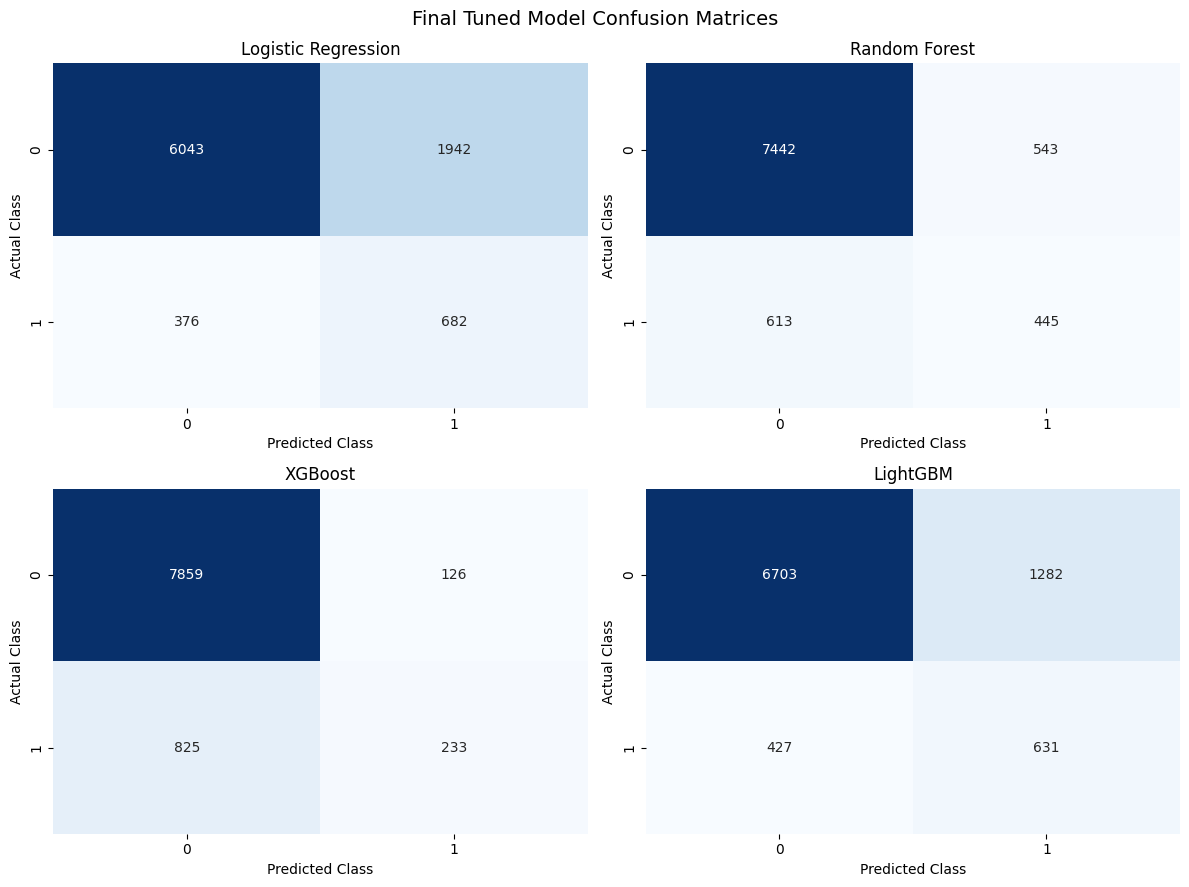

In [56]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes = axes.flatten()

for ax, (model_name, y_pred) in zip(axes, model_predictions.items()):

  cm = confusion_matrix(y_test, y_pred)

  sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)

  ax.set_title(model_name)
  ax.set_xlabel("Predicted Class")
  ax.set_ylabel("Actual Class")

plt.suptitle("Final Tuned Model Confusion Matrices", fontsize = 14)
plt.tight_layout()
plt.show()

Classification Report for Best Model

In [57]:
best_predictions = (model_predictions[final_best_model_name])

print("=" * 70)
print(f"LASSIFICATION REPORT - {final_best_model_name}")
print("=" * 70)

print(classification_report(y_test, best_predictions, digits=4, zero_division=0))

LASSIFICATION REPORT - Random Forest
              precision    recall  f1-score   support

           0     0.9239    0.9320    0.9279      7985
           1     0.4504    0.4206    0.4350      1058

    accuracy                         0.8722      9043
   macro avg     0.6872    0.6763    0.6815      9043
weighted avg     0.8685    0.8722    0.8703      9043



Save Final Best Model

In [58]:
final_best_model = tuned_models[final_best_model_name]

final_model_file = ("IT24102228_final_best_model.joblib")

joblib.dump(final_best_model, final_model_file)

print("=" * 70)
print("FINAL BEST MODEL SAVED")
print("=" * 70)

print("Model:", final_best_model_name)
print("File:", final_model_file)
print(f"Size : {os.path.getsize(final_model_file) / (1024 * 1024):.2f} MB")
print("\n✅ Final best model saved successfully")

FINAL BEST MODEL SAVED
Model: Random Forest
File: IT24102228_final_best_model.joblib
Size : 75.18 MB

✅ Final best model saved successfully


Save Final Evaluation Results

In [59]:
final_evaluation_package = {"results": final_results, "best_model": final_best_model_name, "best_metrics": final_best_metrics.to_dict(), "primary_metric": "F1", "accuracy_target": 0.75, "models_meeting_accuracy_target": accuracy_pass_count}

joblib.dump(final_evaluation_package, "IT24102228_final_evaluation_results.joblib")

print("=" * 70)
print("FINAL EVALUATION RESULTS")
print("=" * 70)

print("✅ Saved: IT24102228_final_evaluation_results.joblib")

FINAL EVALUATION RESULTS
✅ Saved: IT24102228_final_evaluation_results.joblib


Reloaded and Verify Final Best Model

In [60]:
reloaded_final_model = joblib.load("IT24102228_final_best_model.joblib")

reloaded_predictions = (reloaded_final_model.predict(X_test_processed))

original_predictions = (model_predictions[final_best_model_name])

predictions_match = np.array_equal(original_predictions, reloaded_predictions)

print("=" * 70)
print("FINAL MODEL RELOAD VERIFICATION")
print("=" * 70)

print("Model loaded:✅ YES")
print("Predictions identical:✅ YES" if predictions_match else "❌ NO")

FINAL MODEL RELOAD VERIFICATION
Model loaded:✅ YES
Predictions identical:✅ YES


Display All Saved Member 3 Models

In [61]:
member3_files = [
    # Baseline
    "IT24102228_logistic_regression.joblib", "IT24102228_random_forest.joblib", "IT24102228_xgboost.joblib", "IT24102228_lightgbm.joblib", "IT24102228_best_model.joblib",

    # Tuned
    "IT24102228_logistic_regression_tuned.joblib", "IT24102228_random_forest_tuned.joblib", "IT24102228_xgboost_tuned.joblib", "IT24102228_lightgbm.joblib", "IT24102228_best_tuned_model.joblib",

    # Final
    "IT24102228_final_best_model.joblib"
]

print("=" * 75)
print("MEMBER 3 SAVED MODEL ARTIFACTS")
print("=" * 75)

for file in member3_files:
  if os.path.exists(file):

    size_mb = (os.path.getsize(file) / (1024 * 1024))

    print(f"✅ {file:<53} ({size_mb:.2f} MB")

  else:

    print(f"❌ {file:<53} MISSING")

MEMBER 3 SAVED MODEL ARTIFACTS
✅ IT24102228_logistic_regression.joblib                 (0.00 MB
✅ IT24102228_random_forest.joblib                       (273.26 MB
✅ IT24102228_xgboost.joblib                             (0.93 MB
✅ IT24102228_lightgbm.joblib                            (0.99 MB
✅ IT24102228_best_model.joblib                          (0.99 MB
✅ IT24102228_logistic_regression_tuned.joblib           (0.00 MB
✅ IT24102228_random_forest_tuned.joblib                 (75.18 MB
✅ IT24102228_xgboost_tuned.joblib                       (0.54 MB
✅ IT24102228_lightgbm.joblib                            (0.99 MB
✅ IT24102228_best_tuned_model.joblib                    (75.18 MB
✅ IT24102228_final_best_model.joblib                    (75.18 MB


Task 5 Summary

In [62]:
print("=" * 75)
print("MEMBER 3 - TASK 5 COMPLETED")
print("=" * 75)


print(f"""
FINAL TEST EVALUATION
---------------------
✅ Logistic Regression evaluated
✅ Random Forest evaluated
✅ XGBoost evaluated
✅ LightGBM evaluated

METRICS
-------
✅ Accuracy
✅ Precision
✅ Recall
✅ F1-Score
✅ ROC-AUC
✅ PR-AUC
✅ Confusion Matrix

ACCURACY TARGET
---------------
Models >= 75%:
{accuracy_pass_count}/{len(final_results)}

FINAL SELECTED MODEL
--------------------
{final_best_model_name}

Accuracy:
{final_best_metrics['Accuracy'] * 100:.2f}%

F1-Score:
{final_best_metrics['F1']:.4f}

ROC-AUC:
{final_best_metrics['ROC AUC']:.4f}

PR-AUC:
{final_best_metrics['PR AUC']:.4f}

FINAL MODEL ARTIFACT
--------------------
✅ IT24102228_final_best_model.joblib

FINAL RESULTS ARTIFACT
----------------------
✅ IT24102228_final_evaluation_results.joblib

MODEL RELOAD CHECK
------------------
{'✅ PASS' if predictions_match else '❌ FAIL'}

MEMBER 3 FINAL MODELLING PIPELINE
--------------------------------
Baseline Models
      ↓
Hyperparameter Tuning
      ↓
Tuned Models
      ↓
Final Test Evaluation
      ↓
F1-Based Model Comparison
      ↓
Final Best Model
      ↓
.joblib Serialization
      ↓
Reload Verification ✅
""")


print("=" * 75)

MEMBER 3 - TASK 5 COMPLETED

FINAL TEST EVALUATION
---------------------
✅ Logistic Regression evaluated
✅ Random Forest evaluated
✅ XGBoost evaluated
✅ LightGBM evaluated

METRICS
-------
✅ Accuracy
✅ Precision
✅ Recall
✅ F1-Score
✅ ROC-AUC
✅ PR-AUC
✅ Confusion Matrix

ACCURACY TARGET
---------------
Models >= 75%:
3/4

FINAL SELECTED MODEL
--------------------
Random Forest

Accuracy:
87.22%

F1-Score:
0.4350

ROC-AUC:
0.7800

PR-AUC:
0.4225

FINAL MODEL ARTIFACT
--------------------
✅ IT24102228_final_best_model.joblib

FINAL RESULTS ARTIFACT
----------------------
✅ IT24102228_final_evaluation_results.joblib

MODEL RELOAD CHECK
------------------
✅ PASS

MEMBER 3 FINAL MODELLING PIPELINE
--------------------------------
Baseline Models
      ↓
Hyperparameter Tuning
      ↓
Tuned Models
      ↓
Final Test Evaluation
      ↓
F1-Based Model Comparison
      ↓
Final Best Model
      ↓
.joblib Serialization
      ↓
Reload Verification ✅

